# Decomposing RNNs

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path

device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
mu = np.array([
    [1,2],
    [-1.5,0],
    [1,-2.25]
]).T

sigma = 0.75*np.ones(mu.shape[1])
A = 0.25*np.ones(mu.shape[1])

(u_x,u_y), r = h.intersecting_circle(mu)

c = [u_x, u_y]

theta = 1

M = np.array([
    [0,theta],
    [-theta,0]
])

xi = 0.6
nu = 0.2
alpha = 1.5

mu_np = mu.T.copy() 
mu_t = torch.from_numpy(mu_np).to(device=device, dtype=torch.float32)   # (K,2)
A_t = torch.from_numpy(A.astype(np.float32)).to(device=device)          # (K,)
sigma_t = torch.from_numpy(sigma.astype(np.float32)).to(device=device)  # (K,)

c_t = torch.tensor([u_x, u_y], device=device, dtype=torch.float32)   # (2,)
r_t = float(r)
xi_t = float(xi)
M_t = torch.from_numpy(M.astype(np.float32)).to(device=device)       # (2,2)
alpha_t = float(alpha)
nu_t = float(nu)

def gaussian_potential_vectorized_torch(x):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
   
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)   # (B, K, 2)
    sq = (diff * diff).sum(dim=2)               # (B, K)
    denom = 2.0 * (sigma_t ** 2)                # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))
    V = -(A_t.unsqueeze(0) * exp_term).sum(dim=1)   # (B,)
    if is_1d:
        return V[0]
    return V  # (B,)

def grad_gaussian_potential_vectorized_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)        # (B, K, 2)
    sq = (diff * diff).sum(dim=2)                    # (B, K)
    denom = 2.0 * (sigma_t ** 2)                     # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))  # (B,K)
    factor = (A_t / (sigma_t ** 2)).unsqueeze(0) * exp_term   # (B,K)
    grad =  (factor.unsqueeze(2) * diff).sum(dim=1)   # (B,2)
    if is_1d:
        return grad[0]
    return grad  # (B,2)

def g_vec_torch(x):
 
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    d = torch.sqrt(((x - c_t.unsqueeze(0))**2).sum(dim=1))  # (B,)
    g = torch.exp(- ((d - r_t)**2) / (2.0 * (xi_t**2)))
    if is_1d:
        return g[0]
    return g  # (B,)

def piZ_vec_torch(x):

    V = gaussian_potential_vectorized_torch(x)  # (B,)
    piz = torch.exp(-2.0 * V / (nu_t**2))
    return piz

def gradV_gMc_pi_vec_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    grad_v = grad_gaussian_potential_vectorized_torch(x)   # (B,2)
    nc = (x - c_t.unsqueeze(0)) @ M_t.T   # (B,2)
    g_scalar = g_vec_torch(x).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = -grad_v + g_scalar * (alpha_t * nc) / piz_clamped
    if is_1d:
        return out[0]
    return out  # (B,2)


def V(x):
    return h.gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return h.grad_gaussian_potential(x,mu,A,sigma)

def g(p):
    x,y = p
    d = np.sqrt((x-u_x)**2 + (y-u_y)**2)
    return np.exp(-((d-r)**2)/(2*xi**2))

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

def gradV_gMc_pi(x):
    grad_v = h.grad_gaussian_potential(x,mu,A,sigma)
    return -grad_v + g(x)*alpha*(M@(x-c))/piZ(x)

xmin = -4; xmax = 4; ymin = -4; ymax = 4

def potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            Z[i, j] = V(x)
    return X, Y, Z

def quiver_grid(F, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 20):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    U = np.zeros_like(X)
    V_ = np.zeros_like(X)
    Unorm = np.zeros_like(X)
    Vnorm = np.zeros_like(X)
    magnitude = np.zeros_like(X)
    
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            f = F(x)
            U[i, j] = f[0]
            V_[i, j] = f[1]
            magnitude[i, j] = np.linalg.norm(f) + 1e-11
            Unorm[i, j] = U[i, j] / magnitude[i, j]
            Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    return  X, Y, Unorm, Vnorm, magnitude, U, V_

In [3]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8):
        super().__init__()
        self.Gamma = nn.Linear(2, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, 2, bias= False)
        self.I_s = nn.Parameter(torch.zeros(2))
        self.B_s = nn.Parameter(torch.randn(2, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [4]:
latent_dim = 128
model = TwoLayerMLP(latent_dim).to(device)

opt = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

n_samples = 25_000
x_train = (torch.rand(n_samples, 2) * 8.0 - 4.0).to(device)
y_train = gradV_gMc_pi_vec_torch(x_train).to(device)
_eye2 = torch.eye(2, device=device)
D_target = (nu_t**2) * _eye2  

lambda_diff = 20
epochs = 30_000

for epoch in trange(epochs, desc= 'training MLP'):
    opt.zero_grad()
    
    pred = model(x_train)
    
    drift_loss = loss_fn(pred, y_train)

    D_model = model.B_s@(model.B_s.T)
    diffusion_loss = torch.norm(D_model - D_target, p='fro')**2
    
    loss = drift_loss + lambda_diff*diffusion_loss
    loss.backward()
    opt.step()
    
    if (epoch + 1) % 1000 == 0:
        print(f"epoch {epoch+1:4d} loss: {loss.item():.6f} drift: {drift_loss:.6f} diff: {diffusion_loss:.6f}")

training MLP:   3%|▊                      | 1013/30000 [00:06<04:07, 116.95it/s]

epoch 1000 loss: 416.618469 drift: 0.087450 diff: 20.826550


training MLP:   7%|█▌                     | 2017/30000 [00:13<03:14, 143.58it/s]

epoch 2000 loss: 89.401932 drift: 0.058913 diff: 4.467151


training MLP:  10%|██▎                    | 3021/30000 [00:21<04:02, 111.43it/s]

epoch 3000 loss: 25.047293 drift: 0.030586 diff: 1.250835


... (50 outputs left out)

training MLP:  97%|█████████████████████▎| 29027/30000 [03:29<00:06, 143.88it/s]

epoch 29000 loss: 0.000282 drift: 0.000282 diff: 0.000000


training MLP: 100%|██████████████████████| 30000/30000 [03:35<00:00, 138.95it/s]

epoch 30000 loss: 0.000275 drift: 0.000275 diff: 0.000000


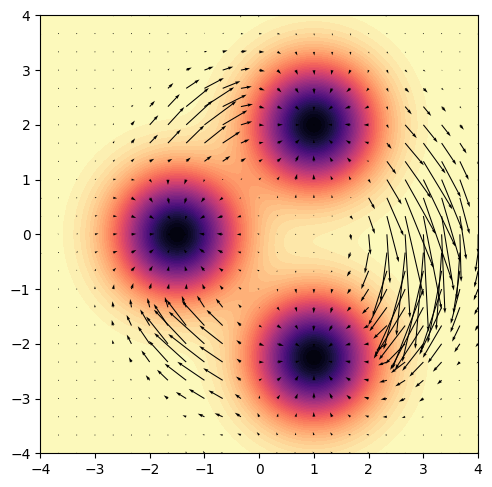

In [8]:
grid_lim = 4; grid_res = 25
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

fig, ax = plt.subplots(1, 1, figsize=(5,5))

X, Y, Z = potential_grid(V)
ax.contourf(X, Y, Z, levels=50, cmap='magma')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)


with torch.no_grad():
    F_model = model(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
U_t, V_t = F_model[:,0].reshape(grid_res,grid_res).numpy(), F_model[:,1].reshape(grid_res,grid_res).numpy()

ax.quiver(Xn, Yn, U_t, V_t)
ax.set_xlim(-grid_lim, grid_lim)
ax.set_ylim(-grid_lim, grid_lim)
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

In [9]:
print(model.B_s@(model.B_s.T))

Gamma = model.Gamma.weight.detach()
Gamma_pinv = torch.linalg.pinv(Gamma).detach()
b = model.input_bias.detach()
W = Gamma @ model.W_s.weight.detach() 
I = Gamma @ model.I_s.detach() +  b
B = Gamma @ model.B_s.detach()

print(Gamma_pinv@Gamma)

tensor([[ 4.0005e-02, -3.6258e-06],
        [-3.6258e-06,  4.0000e-02]], grad_fn=<MmBackward0>)
tensor([[1.0000e+00, 2.9802e-08],
        [2.6077e-08, 1.0000e+00]])


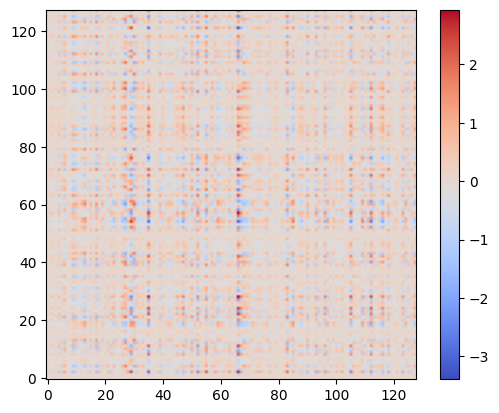

In [10]:
fig, ax = plt.subplots(1,1)

ax.imshow(W, origin= 'lower', cmap = 'coolwarm')
im = ax.imshow(W, origin='lower', cmap='coolwarm')

fig.colorbar(im, ax=ax)

We would like to decompose the RNN dynamics, but also to fit part of the network which approximates each of these components.

In [2]:
def f_rev(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    grad_v = grad_gaussian_potential_vectorized_torch(x)
    out = -grad_v
    if is_1d:
        return out[0]
    return out  # (B,2)

def f_irr(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = (x - c_t.unsqueeze(0)) @ M_t.T   # (B,2)
    g_scalar = g_vec_torch(x).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = g_scalar * (alpha_t * nc) / piz_clamped
    if is_1d:
        return out[0]
    return out  # (B,2)

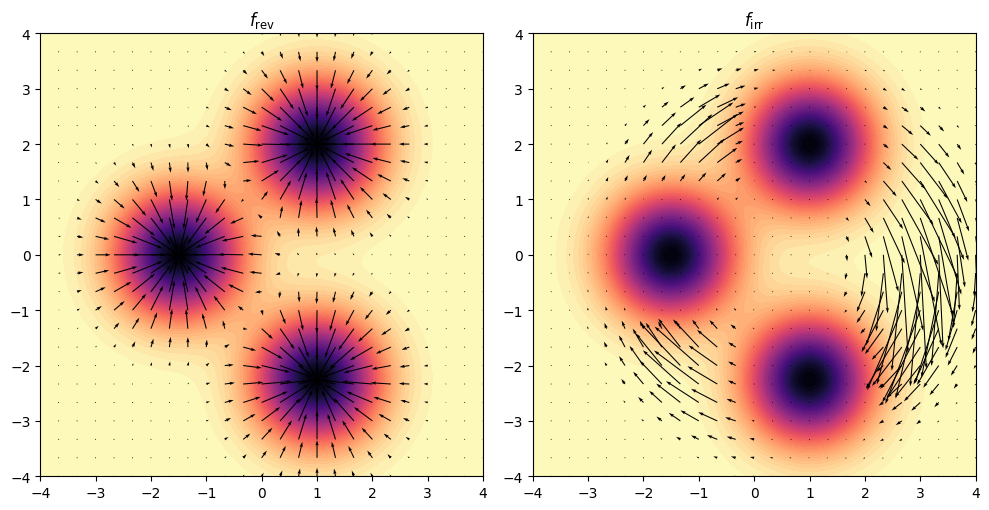

In [12]:
grid_lim = 4; grid_res = 25
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

fig, ax = plt.subplots(1, 2, figsize=(10,5))


X, Y, Z = potential_grid(V)
ax[0].contourf(X, Y, Z, levels=50, cmap='magma')
ax[1].contourf(X, Y, Z, levels=50, cmap='magma')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    f_r = f_rev(grid_points).cpu()
    f_i = f_irr(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
U_t, V_t = f_r[:,0].reshape(grid_res,grid_res).numpy(), f_r[:,1].reshape(grid_res,grid_res).numpy()
ax[0].quiver(Xn, Yn, U_t, V_t)
U_t, V_t = f_i[:,0].reshape(grid_res,grid_res).numpy(), f_i[:,1].reshape(grid_res,grid_res).numpy()
ax[1].quiver(Xn, Yn, U_t, V_t)

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

ax[0].set_title(r'$f_{\text{rev}}$')
ax[1].set_title(r'$f_{\text{irr}}$')

plt.tight_layout()
plt.show()

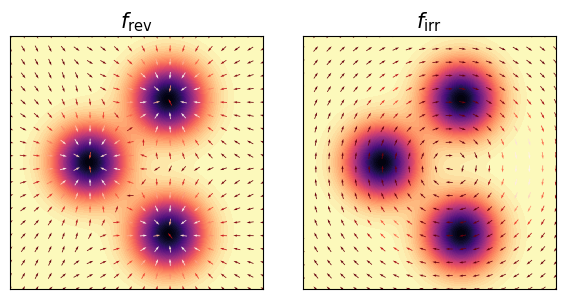

In [86]:
grid_lim = 4; grid_res = 20
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

X, Y, Z = potential_grid(V)
for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma') # Added alpha for better arrow visibility

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    f_r = f_rev(grid_points).cpu()
    f_i = f_irr(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

# Helper function to plot normalized quiver with color
def plot_normalized_quiver(ax, field_data, title):
    U = field_data[:, 0].reshape(grid_res, grid_res).numpy()
    V = field_data[:, 1].reshape(grid_res, grid_res).numpy()
    
    mag = np.sqrt(U**2 + V**2)
    
    U_norm = U / (mag + 1e-9)
    V_norm = V / (mag + 1e-9)
    
    q = ax.quiver(Xn, Yn, U_norm, V_norm, mag, 
                  cmap='Reds_r', 
                  pivot='mid')      
    
    ax.set_title(title, fontsize = 15)

plot_normalized_quiver(ax[0], f_r, r'$f_{\text{rev}}$')
plot_normalized_quiver(ax[1], f_i, r'$f_{\text{irr}}$')

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11567/3451114648.py:11: UserWarning: linewidths is ignored by contourf
  a.contourf(X, Y, Z, levels=50, cmap='magma', antialiased=False, linewidths=0, rasterized=True, alpha = 0.8)
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11567/3451114648.py:11: UserWarning: The following kwargs were not used by contour: 'rasterized'
  a.contourf(X, Y, Z, levels=50, cmap='magma', antialiased=False, linewidths=0, rasterized=True, alpha = 0.8)


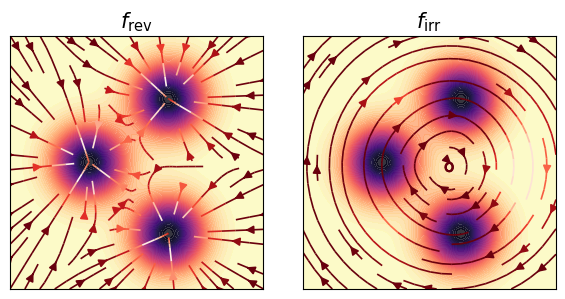

In [15]:
from matplotlib.colors import Normalize

grid_lim = 4; grid_res = 20
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

X, Y, Z = potential_grid(V)
for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma', antialiased=False, linewidths=0, rasterized=True, alpha = 0.8) 

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    f_r = f_rev(grid_points).cpu()
    f_i = f_irr(grid_points).cpu()

xn = xs.numpy()
yn = ys.numpy()

def plot_streamlines(ax, field_data, title):
    U = field_data[:, 0].reshape(grid_res, grid_res).numpy()
    V = field_data[:, 1].reshape(grid_res, grid_res).numpy()
    
    mag = np.sqrt(U**2 + V**2)
    norm = Normalize(vmin=mag.min(), vmax=mag.max())
    
    ax.streamplot(
        xn, yn, 
        U, V, 
        color=mag, 
        cmap='Reds_r', 
        norm=norm,
        density=0.6,
        linewidth=1.2, 
        arrowsize=1.2
    )      
    
    ax.set_title(title, fontsize=15)

plot_streamlines(ax[0], f_r, r'$f_{\text{rev}}$')
plot_streamlines(ax[1], f_i, r'$f_{\text{irr}}$')

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

Let's define the components in the high-dimensional space.

In [87]:
def F_rev(u):
    y = Gamma_pinv@(u - b)
    return Gamma @ f_rev(y)

def F_irr(u):
    y = Gamma_pinv@(u - b)
    return Gamma @ f_irr(y)

Let's integrate these components

In [88]:
def integrate_rev(F, B, dt, T, u0):

    u = B.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
            u_ = u[:, t]
            u[:, t+1] = u_ + dt*(F(u_)) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def integrate_irr(F, dt, T, u0):

    u = B.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
            u_ = u[:, t]
            u[:, t+1] = u_ + dt*(F(u_)) # no noise on irreversible component

    return u

def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

In [18]:
y0 = torch.tensor([-2.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.01; T = 20000; u0 = Gamma @ y0 + b; Nt = int(T/dt)

u_rev = integrate_rev(F_rev, B, dt, T, u0)
y_rev = project_rnn(u_rev, Gamma, b, Gamma_pinv)

u_irr = integrate_irr(F_irr, dt, T, u0)
y_irr = project_rnn(u_irr, Gamma, b, Gamma_pinv)

100%|██████████████████████████████| 1999999/1999999 [01:46<00:00, 18710.74it/s]


KeyboardInterrupt: 

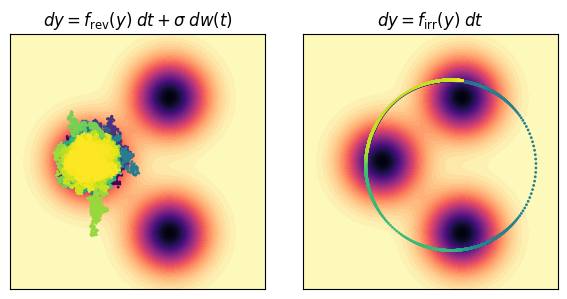

In [89]:
ds = 5

X, Y, Z = potential_grid(V)

fig, ax = plt.subplots(1,2)
fig.set_size_inches(6,3)

time = np.linspace(0,T,int(T/dt))

U_t, V_t = f_r[:,0].reshape(grid_res,grid_res).numpy(), f_r[:,1].reshape(grid_res,grid_res).numpy()
U_t, V_t = f_i[:,0].reshape(grid_res,grid_res).numpy(), f_i[:,1].reshape(grid_res,grid_res).numpy()
for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    
ax[0].scatter(y_rev[0,::ds], y_rev[1,::ds],c=time[::ds],cmap='viridis',s=1, rasterized = True)
ax[1].scatter(y_irr[0,::ds], y_irr[1,::ds],c=time[::ds],cmap='viridis',s=1, rasterized = True)

for a in ax:
    a.set_aspect('equal')
    a.set_xlim([xmin,xmax])
    a.set_ylim([ymin,ymax])
    a.set_xticks([])
    a.set_yticks([])

ax[0].set_title(r'$dy = f_{\text{rev}}(y)\;dt+\sigma\; dw(t)$')
ax[1].set_title(r'$dy = f_{\text{irr}}(y)\;dt$')

plt.tight_layout()
plt.show()

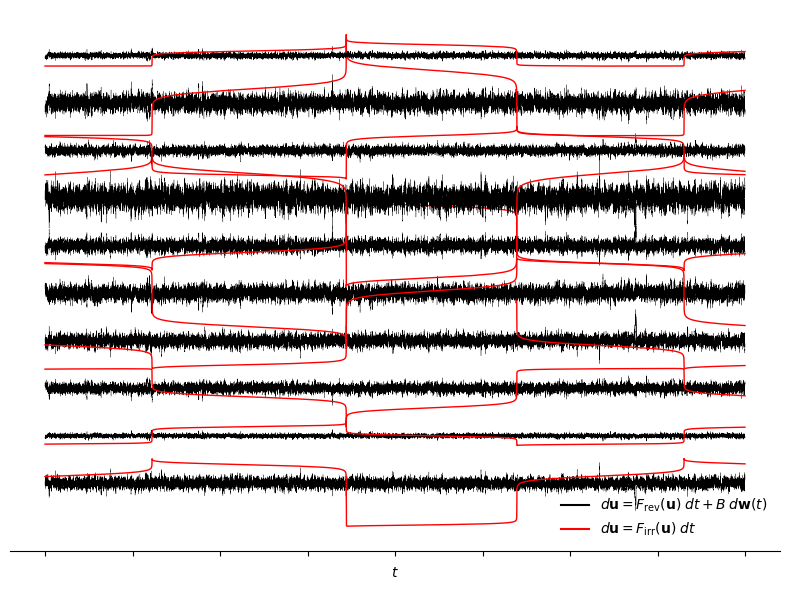

In [68]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(8,6)

num_vis_neurons = 10
vis_neurons = np.random.choice(range(0,latent_dim), num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace_rev = u_rev[v, ::ds] + 5*n - torch.mean(u_rev[v, :])
    trace_irr = u_irr[v, ::ds] + 5*n - torch.mean(u_irr[v, :])
    
    label_rev = r'$d\mathbf{u} = F_{\text{rev}}(\mathbf{u})\; dt + B \;d\mathbf{w}(t)$' if n == 0 else ""
    label_irr = r'$d\mathbf{u} =F_{\text{irr}}(\mathbf{u})\; dt$' if n == 0 else ""

    ax.plot(time[::ds], trace_rev, 'black', linewidth=0.2, label=label_rev)
    ax.plot(time[::ds], trace_irr, 'red', linewidth=1, label=label_irr)

sns.despine(left=True)
plt.gca().get_yaxis().set_visible(False)


leg = ax.legend(loc='lower right', frameon=False)
for line in leg.get_lines():
    line.set_linewidth(1.5)

ax.set_xticklabels([])
ax.set_xlabel(r'$t$')
plt.tight_layout()
plt.show()

So we can do the decomposition, but it doesn't tell us much about the network. Next, we will try and get a network decomposition that fits these two components, and compare it to the other decomposition.



In [18]:
class HHD_JointModel(nn.Module):
    def __init__(self, original_model, latent_dim=64):
        super().__init__()
        self.register_buffer('Gamma', original_model.Gamma.weight.data)    # (latent_dim, 2)
        self.register_buffer('b', original_model.input_bias.data)         # (latent_dim,)
        self.register_buffer('W_s_total', original_model.W_s.weight.data) # (2, latent_dim)
        self.register_buffer('I_s_total', original_model.I_s.data)        # (2,)
        
        self.rho_raw = nn.Parameter(torch.tensor(0.0)) 
        
        self.W_s_rev = nn.Parameter(torch.randn(2, latent_dim) * 0.01)
        self.I_s_rev = nn.Parameter(torch.zeros(2))

    def forward(self, x):
        rho = torch.sigmoid(self.rho_raw)
        
        z = torch.tanh(F.linear(x, self.Gamma, self.b))
        
        W_s_irr = self.W_s_total - self.W_s_rev
        I_s_irr = self.I_s_total - self.I_s_rev
        
        W_rev_term = F.linear(z, self.W_s_rev)
        b_rev_term = F.linear((1 - rho) * self.b, self.W_s_rev)
        
        f_rev = -(1 - rho) * x + W_rev_term + b_rev_term + self.I_s_rev
        
        # 4. Irreversible Component
        # Same logic for the irreversible part
        W_irr_term = F.linear(z, W_s_irr)
        b_irr_term = F.linear(rho * self.b, W_s_irr)
        
        f_irr = -rho * x + W_irr_term + b_irr_term + I_s_irr
        
        return f_rev, f_irr

joint_model = HHD_JointModel(model, latent_dim=latent_dim).to(device)
optimizer = torch.optim.Adam(joint_model.parameters(), lr=1e-3)

In [19]:
trainable_params = [p for p in joint_model.parameters() if p.requires_grad]
opt = torch.optim.Adam(trainable_params, lr=1e-3)

print("Optimiser is optimizing these parameter shapes:")
for i, p in enumerate(trainable_params):
    print(f"{i}: {p.shape}")

loss_fn = nn.MSELoss()

n_samples = 25_000
x_train = (torch.rand(n_samples, 2) * 8.0 - 4.0).to(device)
y_rev_train = f_rev(x_train).to(device)
y_irr_train = f_irr(x_train).to(device)

epochs = 30_000

for epoch in trange(epochs, desc='training joint HHD'):
    opt.zero_grad()
    
    pred_rev, pred_irr = joint_model(x_train)
    
    loss_rev = loss_fn(pred_rev, y_rev_train)
    loss_irr = loss_fn(pred_irr, y_irr_train)
    
    total_loss = loss_rev + loss_irr
    
    total_loss.backward()
    opt.step()
    
    if (epoch + 1) % 1000 == 0:
        rho_val = torch.sigmoid(joint_model.rho_raw).item()
        print(f"epoch {epoch+1:4d} | Total Loss: {total_loss:.6f} | rho: {rho_val:.4f}")

Optimiser is optimizing these parameter shapes:
0: torch.Size([])
1: torch.Size([2, 128])
2: torch.Size([2])


training joint HHD:   3%|▌                | 1012/30000 [00:10<04:49, 100.10it/s]

epoch 1000 | Total Loss: 0.027167 | rho: 0.3151


training joint HHD:   7%|█▏               | 2019/30000 [00:20<04:33, 102.28it/s]

epoch 2000 | Total Loss: 0.011036 | rho: 0.3059


training joint HHD:  10%|█▋               | 3013/30000 [00:30<04:24, 101.95it/s]

... (51 outputs left out)

training joint HHD:  97%|███████████████▍| 29012/30000 [04:07<00:07, 128.24it/s]

epoch 29000 | Total Loss: 0.000623 | rho: 0.2569


training joint HHD: 100%|████████████████| 30000/30000 [04:14<00:00, 117.73it/s]

epoch 30000 | Total Loss: 0.000659 | rho: 0.2564


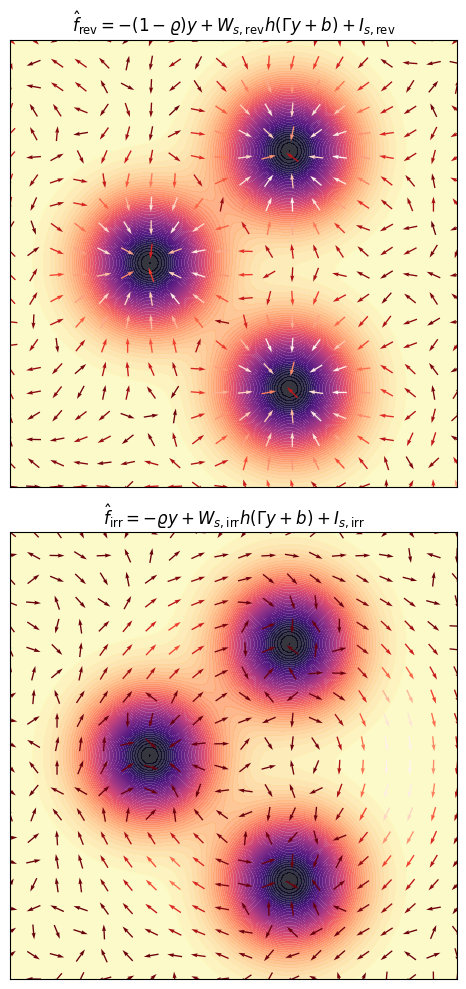

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(5,10))

X, Y, Z = potential_grid(V)
for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma', alpha=0.8)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

joint_model.eval()
with torch.no_grad():
    F_r_torch, F_i_torch = joint_model(grid_points)
    
    F_r = F_r_torch.cpu().numpy()
    F_i = F_i_torch.cpu().numpy()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

def plot_field(ax, data, title):
    U = data[:, 0].reshape(grid_res, grid_res)
    V = data[:, 1].reshape(grid_res, grid_res)
    
    mag = np.sqrt(U**2 + V**2)
    
    U_norm = U / (mag + 1e-9)
    V_norm = V / (mag + 1e-9)
    
    q = ax.quiver(Xn, Yn, U_norm, V_norm, mag, 
                  cmap='Reds_r', pivot='mid', scale=30)
    
    ax.set_title(title)

plot_field(ax[0], F_r, r'$\hat{f}_{\text{rev}}=-(1-\varrho)y + W_{s,\text{rev}}h(\Gamma y + b) + I_{s,\text{rev}} $')
plot_field(ax[1], F_i, r'$\hat{f}_{\text{irr}}=-\varrho y + W_{s,\text{irr}}h(\Gamma y + b) + I_{s,\text{irr}} $')

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()


plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11567/3387866790.py:5: UserWarning: linewidths is ignored by contourf
  a.contourf(
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11567/3387866790.py:5: UserWarning: The following kwargs were not used by contour: 'rasterized'
  a.contourf(


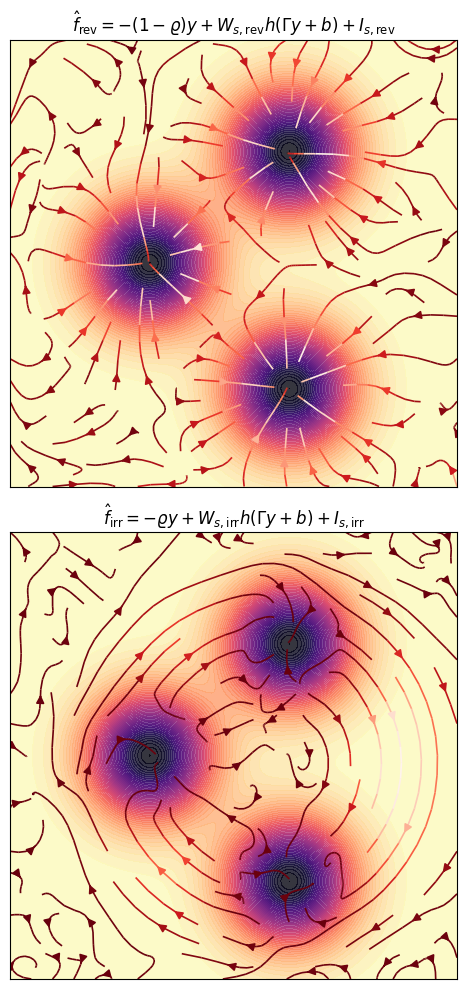

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(5,10))

X, Y, Z = potential_grid(V)
for a in ax:
    a.contourf(
        X, Y, Z, 
        levels=50, 
        cmap='magma', 
        alpha=0.8,
        antialiased=False, 
        linewidths=0, 
        rasterized=True
    )

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

joint_model.eval()
with torch.no_grad():
    F_r_torch, F_i_torch = joint_model(grid_points)
    
    F_r = F_r_torch.cpu().numpy()
    F_i = F_i_torch.cpu().numpy()

# 1D arrays are best for streamplot
xn = xs.numpy()
yn = ys.numpy()

def plot_field(ax, data, title):
    U = data[:, 0].reshape(grid_res, grid_res)
    V = data[:, 1].reshape(grid_res, grid_res)
    
    mag = np.sqrt(U**2 + V**2)
    norm = Normalize(vmin=mag.min(), vmax=mag.max())
    
    # Swapped quiver for streamplot
    ax.streamplot(
        xn, yn, 
        U, V, 
        color=mag, 
        cmap='Reds_r', 
        norm=norm,
        density=0.75,       # Adjust for more/fewer lines
        linewidth=1.2, 
        arrowsize=1.2
    )
    
    ax.set_title(title)

plot_field(ax[0], F_r, r'$\hat{f}_{\text{rev}}=-(1-\varrho)y + W_{s,\text{rev}}h(\Gamma y + b) + I_{s,\text{rev}} $')
plot_field(ax[1], F_i, r'$\hat{f}_{\text{irr}}=-\varrho y + W_{s,\text{irr}}h(\Gamma y + b) + I_{s,\text{irr}} $')

for a in ax:
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

In [139]:
C = 0.5*(W + W.T)

Omega = Gamma_pinv@C@Gamma@(Gamma_pinv)

W_sym = Gamma@Omega
W_asym = W - W_sym

with torch.no_grad():

    W_rev_mat = (joint_model.Gamma @ joint_model.W_s_rev).cpu().numpy()
    W_s_irr = joint_model.W_s_total - joint_model.W_s_rev
    W_irr_mat = (joint_model.Gamma @ W_s_irr).cpu().numpy()

abs_max = max([np.abs(W_rev_mat).max(), np.abs(W_irr_mat).max(), np.abs(W_sym).max(), np.abs(W_asym).max()])

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_44137/316101936.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  abs_max = max([np.abs(W_rev_mat).max(), np.abs(W_irr_mat).max(), np.abs(W_sym).max(), np.abs(W_asym).max()])


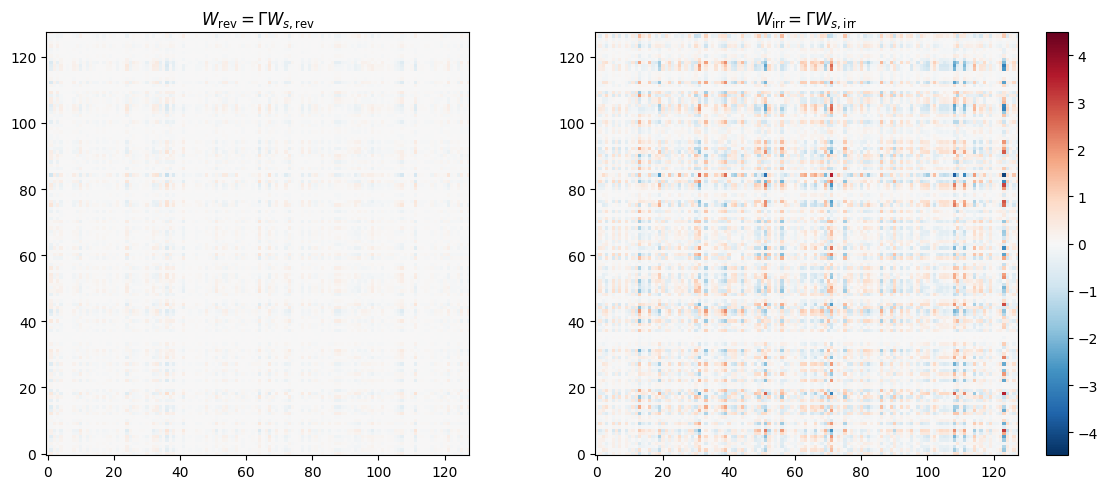

In [162]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im0 = ax[0].imshow(W_rev_mat, cmap='RdBu_r', vmin=-abs_max, vmax=abs_max, origin = 'lower')
ax[0].set_title(r'$W_{\text{rev}} = \Gamma W_{s, \text{rev}}$')

im1 = ax[1].imshow(W_irr_mat, cmap='RdBu_r', vmin=-abs_max, vmax=abs_max, origin = 'lower')
ax[1].set_title(r'$W_{\text{irr}} = \Gamma W_{s, \text{irr}}$')
fig.colorbar(im1, ax=ax[1])

plt.tight_layout()
plt.savefig("hhd_connectivity.pdf", bbox_inches='tight', pad_inches=0.1, dpi=600)    
plt.show()

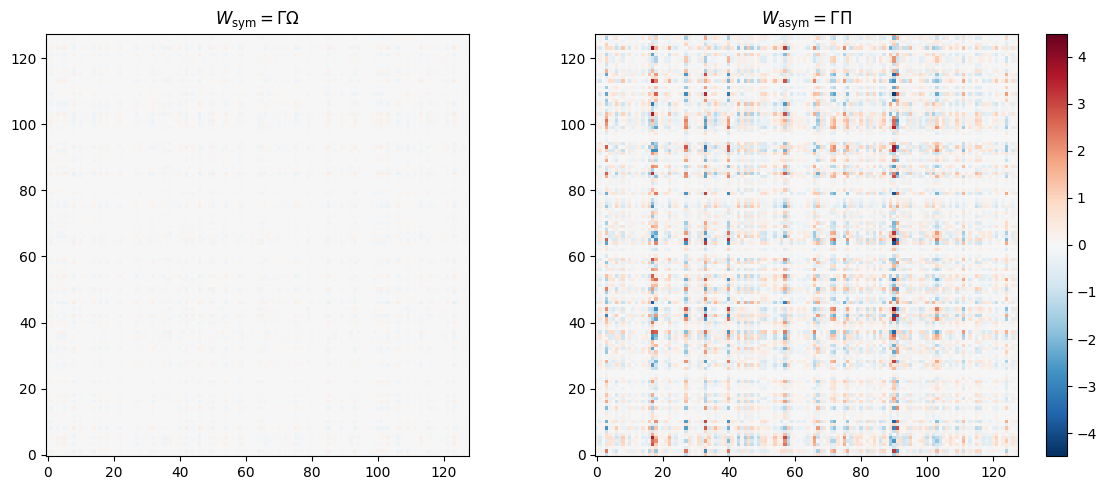

In [163]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

im0 = ax[0].imshow(W_sym, cmap='RdBu_r', vmin=-abs_max, vmax=abs_max, origin = 'lower')
ax[0].set_title(r'$W_{\text{sym}} = \Gamma \Omega$')

im1 = ax[1].imshow(W_asym, cmap='RdBu_r', vmin=-abs_max, vmax=abs_max, origin = 'lower')
ax[1].set_title(r'$W_{\text{asym}} = \Gamma \Pi$')
fig.colorbar(im1, ax=ax[1])

plt.tight_layout()
plt.show()

In [145]:
with torch.no_grad():
    rho = torch.sigmoid(joint_model.rho_raw)
    Gamma = joint_model.Gamma
    b = joint_model.b
    
    I_s_rev = joint_model.I_s_rev
    I_rev = (Gamma @ I_s_rev + (1 - rho) * b).cpu().numpy()
    
    I_s_irr = joint_model.I_s_total - joint_model.I_s_rev
    I_irr = (Gamma @ I_s_irr + rho * b).cpu().numpy()

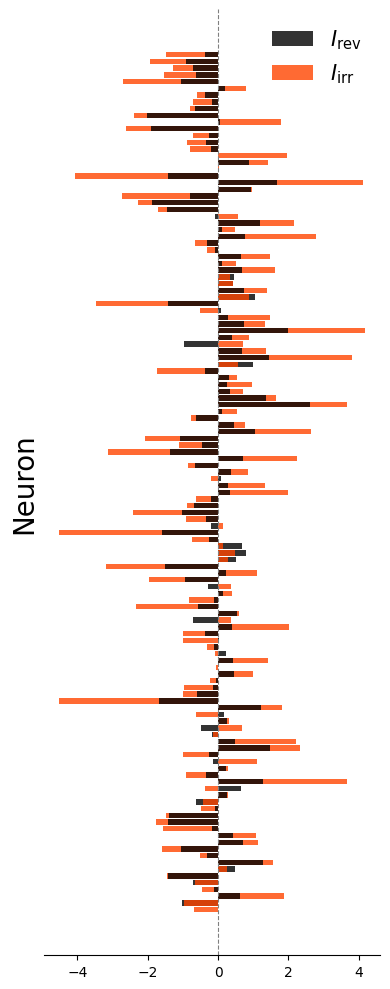

In [164]:
indices = np.arange(len(I_rev))
abs_rev = np.abs(I_rev)
abs_irr = np.abs(I_irr)

rev_taller = abs_rev >= abs_irr
irr_taller = ~rev_taller

fig, ax = plt.subplots(figsize=(4, 10))

ax.barh(indices[rev_taller], I_rev[rev_taller], color='black', alpha=0.8, label=r'$I_{\text{rev}}$')
ax.barh(indices[irr_taller], I_irr[irr_taller], color='orangered', alpha=0.8, label=r'$I_{\text{irr}}$')

ax.barh(indices[rev_taller], I_irr[rev_taller], color='orangered', alpha=0.8)
ax.barh(indices[irr_taller], I_rev[irr_taller], color='black', alpha=0.8)

ax.axvline(0, color='gray', linewidth=0.8, linestyle='--') # Vertical line at 0
ax.set_ylabel('Neuron', fontsize=20)
ax.set_yticks([]) # Hide neuron indices
ax.legend(frameon=False, fontsize=15, loc='upper right')

sns.despine(left=True)

plt.tight_layout()
plt.show()